# 04 - SHAP: why did the model predict this RUL?

SHAP splits every prediction into one contribution per feature:

**predicted RUL = base value (average prediction) + sum of SHAP values**

Positive SHAP = pushes RUL **up** (healthier). Negative SHAP = pushes RUL **down** (closer to failure).

## 1. Train the model (same as 02_baselines)

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from aerohealth import summarize, feature_names, train_xgb

d = np.load("../data/processed/fd001_windows.npz")
names = feature_names(list(d["features"]))     # 90 names like "s11_slope"

model = train_xgb(summarize(d["X_tr"]), d["y_tr"])
F_test = summarize(d["X_test"])                # 100 test engines x 90 features
y_test = d["y_test"]
pred = model.predict(F_test)
print("test RMSE:", round(float(np.sqrt(np.mean((y_test - pred) ** 2))), 2))

/Users/chintansood7/miniforge3/envs/aerohealth/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


test RMSE: 14.09


## 2. SHAP values

In [2]:
explainer = shap.TreeExplainer(model)
sv = explainer(F_test)                         # SHAP values for every engine and feature
sv.feature_names = names

base = sv.base_values[0]
print("base value:", round(float(base), 2))
print("check, base + sum of SHAP - prediction:", float(np.abs(base + sv.values.sum(1) - pred).max()))

base value: 80.77
check, base + sum of SHAP - prediction: 0.00016021728515625


## 3. Which features matter overall?
One dot per engine. Red = high feature value, blue = low. Left of 0 = shortens predicted life.

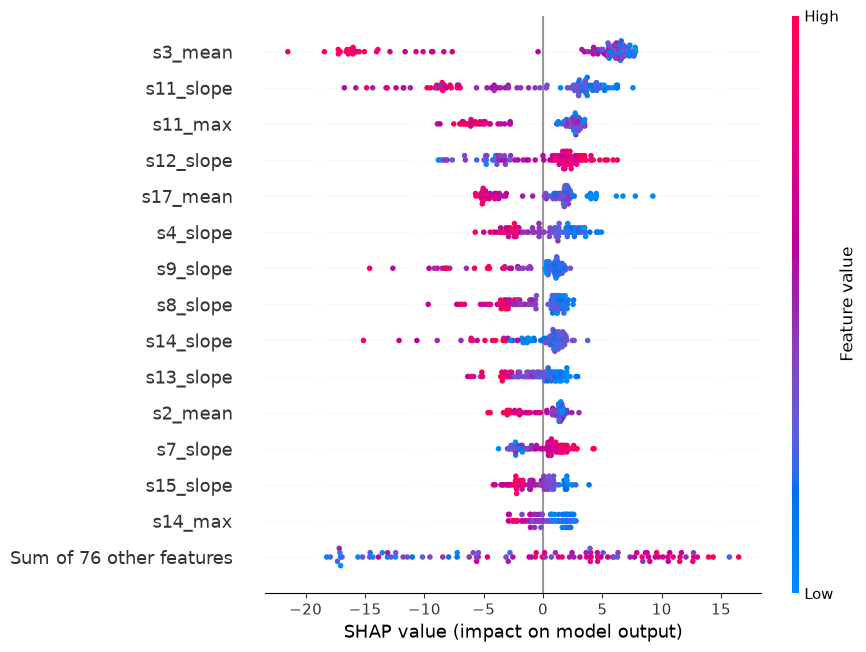

In [3]:
shap.plots.beeswarm(sv, max_display=15, show=False)
plt.savefig("../results/shap_beeswarm_xgb.png", dpi=150, bbox_inches="tight")
plt.show()

Importance = average size of a feature's SHAP value. Add it up per sensor (s11, s3, ...) and per statistic (slope, mean, ...).

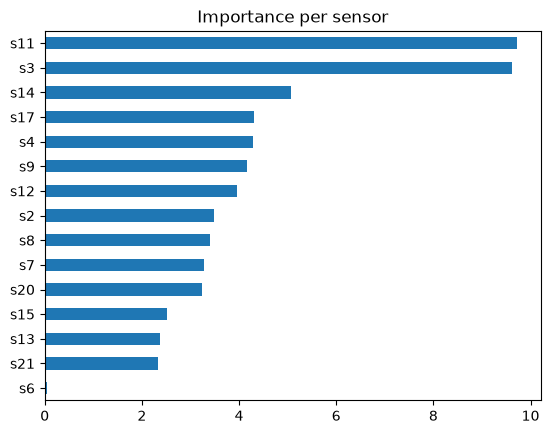

slope    43.3
mean     26.1
max      15.6
min       8.5
std       5.5
last      1.0
dtype: float64


In [4]:
imp = pd.Series(np.abs(sv.values).mean(0), index=names, dtype=float)
sensor = [n.split("_")[0] for n in names]      # "s11_slope" -> "s11"
stat = [n.split("_")[1] for n in names]        # "s11_slope" -> "slope"

imp.groupby(sensor).sum().sort_values().plot.barh(title="Importance per sensor")
plt.savefig("../results/shap_sensor_importance_xgb.png", dpi=150, bbox_inches="tight")
plt.show()

per_stat = imp.groupby(stat).sum()
print((per_stat / per_stat.sum() * 100).round(1).sort_values(ascending=False))

**Reading:** s11 and s3 are the top sensors. Both sit at the **HPC** (high-pressure compressor), and FD001's only fault
is HPC degradation, so the model found the right part. The **slope** (trend) matters most and the **last** reading hardly at all.

## 4. Explain one engine: the most at-risk one

engine 68: predicted RUL 7.0, true RUL 8


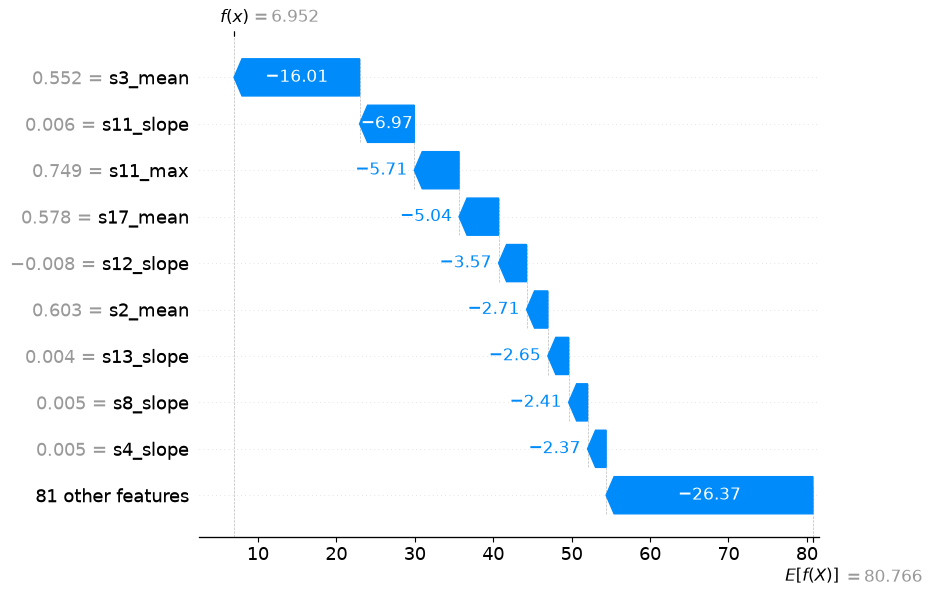

In [5]:
i = pred.argmin()                              # row i = test engine i + 1
print(f"engine {i + 1}: predicted RUL {pred[i]:.1f}, true RUL {y_test[i]:.0f}")

shap.plots.waterfall(sv[i], max_display=10, show=False)
plt.savefig(f"../results/shap_waterfall_engine{i + 1}.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Top 3 reasons for every engine

In [6]:
rows = []
for i in range(len(pred)):
    top3 = pd.Series(np.abs(sv.values[i]), index=names).nlargest(3).index
    rows.append([i + 1, round(float(pred[i]), 1), int(y_test[i]), *top3])

drivers = pd.DataFrame(rows, columns=["engine", "pred_RUL", "true_RUL", "driver1", "driver2", "driver3"])
drivers.to_csv("../results/shap_top_drivers_xgb.csv", index=False)
drivers.sort_values("pred_RUL").head(10)

,engine,pred_RUL,true_RUL,driver1,driver2,driver3
67,68,7.0,8,s3_mean,s11_slope,s11_max
33,34,7.2,7,s3_mean,s11_slope,s11_max
75,76,8.0,10,s3_mean,s11_slope,s11_max
81,82,8.3,9,s3_mean,s11_slope,s11_max
80,81,8.3,8,s3_mean,s11_slope,s11_max
30,31,9.1,8,s3_mean,s11_slope,s11_max
19,20,11.1,16,s3_mean,s11_slope,s11_max
41,42,12.2,10,s3_mean,s11_slope,s11_max
48,49,12.6,21,s3_mean,s11_slope,s11_max
55,56,16.8,15,s3_mean,s11_max,s11_slope


**Caution:** SHAP shows what the **model** uses, not physical cause and effect. Sensors that move together share importance.